In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Housing.csv to Housing.csv


In [3]:
df = pd.read_csv("Housing.csv")

print(df.head())

      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(545, 13)

Column Names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea       

In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [6]:
print("Total Duplicate Rows:")
print(df.duplicated().sum())

Total Duplicate Rows:
0


In [7]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

Before removing duplicates: (545, 13)
After removing duplicates: (545, 13)


In [8]:
print(df.isnull().sum())

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [9]:
df = df.dropna()

In [10]:
print(df.dtypes)

price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


In [11]:
df['mainroad'] = df['mainroad'].map({'yes': 1, 'no': 0})

df['guestroom'] = df['guestroom'].map({'yes': 1, 'no': 0})

df['basement'] = df['basement'].map({'yes': 1, 'no': 0})

df['hotwaterheating'] = df['hotwaterheating'].map({'yes': 1, 'no': 0})

df['airconditioning'] = df['airconditioning'].map({'yes': 1, 'no': 0})

df['prefarea'] = df['prefarea'].map({'yes': 1, 'no': 0})

df['furnishingstatus'] = df['furnishingstatus'].map({
    'furnished': 2,
    'semi-furnished': 1,
    'unfurnished': 0
})

print(df.head())

      price  area  bedrooms  bathrooms  stories  mainroad  guestroom  \
0  13300000  7420         4          2        3         1          0   
1  12250000  8960         4          4        4         1          0   
2  12250000  9960         3          2        2         1          0   
3  12215000  7500         4          2        2         1          0   
4  11410000  7420         4          1        2         1          1   

   basement  hotwaterheating  airconditioning  parking  prefarea  \
0         0                0                1        2         1   
1         0                0                1        3         0   
2         1                0                0        2         1   
3         1                0                1        3         1   
4         1                0                1        2         0   

   furnishingstatus  
0                 2  
1                 2  
2                 1  
3                 2  
4                 2  


In [12]:
print(df.head(10))

      price   area  bedrooms  bathrooms  stories  mainroad  guestroom  \
0  13300000   7420         4          2        3         1          0   
1  12250000   8960         4          4        4         1          0   
2  12250000   9960         3          2        2         1          0   
3  12215000   7500         4          2        2         1          0   
4  11410000   7420         4          1        2         1          1   
5  10850000   7500         3          3        1         1          0   
6  10150000   8580         4          3        4         1          0   
7  10150000  16200         5          3        2         1          0   
8   9870000   8100         4          1        2         1          1   
9   9800000   5750         3          2        4         1          1   

   basement  hotwaterheating  airconditioning  parking  prefarea  \
0         0                0                1        2         1   
1         0                0                1        3      

In [13]:
print(df.describe())

              price          area    bedrooms   bathrooms     stories  \
count  5.450000e+02    545.000000  545.000000  545.000000  545.000000   
mean   4.766729e+06   5150.541284    2.965138    1.286239    1.805505   
std    1.870440e+06   2170.141023    0.738064    0.502470    0.867492   
min    1.750000e+06   1650.000000    1.000000    1.000000    1.000000   
25%    3.430000e+06   3600.000000    2.000000    1.000000    1.000000   
50%    4.340000e+06   4600.000000    3.000000    1.000000    2.000000   
75%    5.740000e+06   6360.000000    3.000000    2.000000    2.000000   
max    1.330000e+07  16200.000000    6.000000    4.000000    4.000000   

         mainroad   guestroom    basement  hotwaterheating  airconditioning  \
count  545.000000  545.000000  545.000000       545.000000       545.000000   
mean     0.858716    0.177982    0.350459         0.045872         0.315596   
std      0.348635    0.382849    0.477552         0.209399         0.465180   
min      0.000000    0.000

In [14]:
print(df.corr())

                     price      area  bedrooms  bathrooms   stories  mainroad  \
price             1.000000  0.535997  0.366494   0.517545  0.420712  0.296898   
area              0.535997  1.000000  0.151858   0.193820  0.083996  0.288874   
bedrooms          0.366494  0.151858  1.000000   0.373930  0.408564 -0.012033   
bathrooms         0.517545  0.193820  0.373930   1.000000  0.326165  0.042398   
stories           0.420712  0.083996  0.408564   0.326165  1.000000  0.121706   
mainroad          0.296898  0.288874 -0.012033   0.042398  0.121706  1.000000   
guestroom         0.255517  0.140297  0.080549   0.126469  0.043538  0.092337   
basement          0.187057  0.047417  0.097312   0.102106 -0.172394  0.044002   
hotwaterheating   0.093073 -0.009229  0.046049   0.067159  0.018847 -0.011781   
airconditioning   0.452954  0.222393  0.160603   0.186915  0.293602  0.105423   
parking           0.384394  0.352980  0.139270   0.177496  0.045547  0.204433   
prefarea          0.329777  

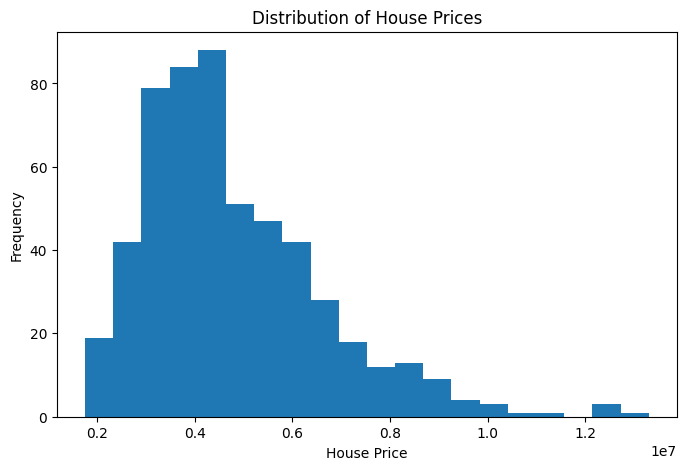

In [15]:
plt.figure(figsize=(8,5))

plt.hist(df['price'], bins=20)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

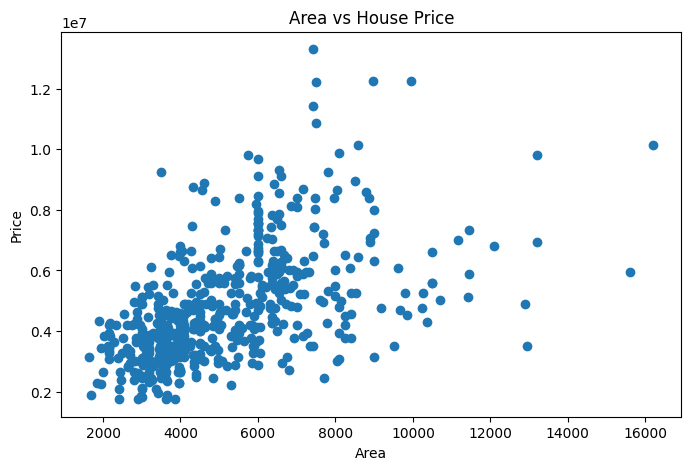

In [16]:
plt.figure(figsize=(8,5))

plt.scatter(df['area'], df['price'])

plt.title("Area vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")

plt.show()

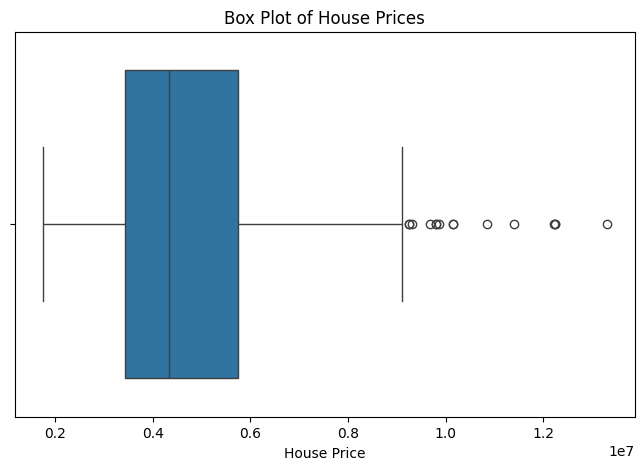

In [17]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['price'])

plt.title("Box Plot of House Prices")
plt.xlabel("House Price")

plt.show()

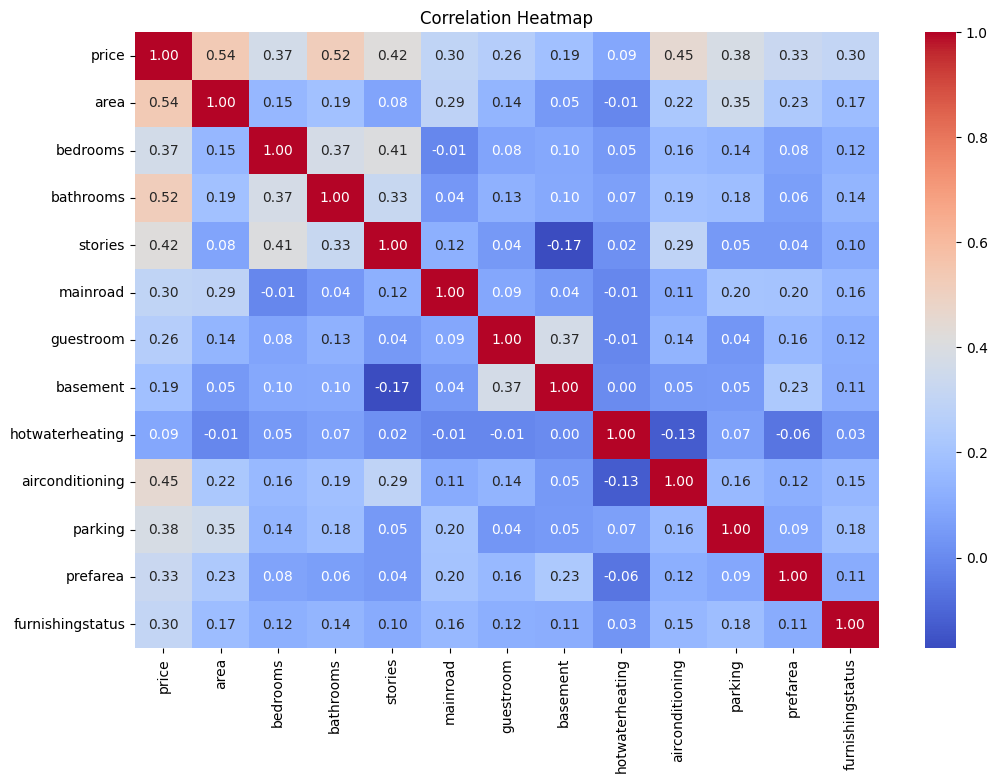

In [18]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [19]:
X = df.drop('price', axis=1)

y = df['price']

print("Independent Variables:")
print(X.head())

print("\nDependent Variable:")
print(y.head())

Independent Variables:
   area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  \
0  7420         4          2        3         1          0         0   
1  8960         4          4        4         1          0         0   
2  9960         3          2        2         1          0         1   
3  7500         4          2        2         1          0         1   
4  7420         4          1        2         1          1         1   

   hotwaterheating  airconditioning  parking  prefarea  furnishingstatus  
0                0                1        2         1                 2  
1                0                1        3         0                 2  
2                0                0        2         1                 1  
3                0                1        3         1                 2  
4                0                1        2         0                 2  

Dependent Variable:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Nam

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (436, 12)
Testing Data: (109, 12)


In [21]:
X_simple = df[['area']]
y_simple = df['price']

print(X_simple.head())
print(y_simple.head())

   area
0  7420
1  8960
2  9960
3  7500
4  7420
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


In [22]:
x = df['area']
y = df['price']

x_mean = np.mean(x)
y_mean = np.mean(y)

print("Mean of X:", x_mean)
print("Mean of Y:", y_mean)

Mean of X: 5150.54128440367
Mean of Y: 4766729.247706422


In [23]:
numerator = np.sum((x - x_mean) * (y - y_mean))

denominator = np.sum((x - x_mean) ** 2)

b1 = numerator / denominator

print("Slope (b1):", b1)

Slope (b1): 461.9748942727835


In [24]:
b0 = y_mean - (b1 * x_mean)

print("Intercept (b0):", b0)

Intercept (b0): 2387308.48239643


In [25]:
y_pred_manual = b0 + b1 * x

print("Actual Prices:")
print(y.head())

print("\nPredicted Prices:")
print(y_pred_manual.head())

Actual Prices:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64

Predicted Prices:
0    5.815162e+06
1    6.526604e+06
2    6.988578e+06
3    5.852120e+06
4    5.815162e+06
Name: area, dtype: float64


In [26]:
result = pd.DataFrame()

result['Actual Price'] = y

result['Predicted Price'] = y_pred_manual

result['Residual'] = y - y_pred_manual

result['Squared Error'] = result['Residual'] ** 2

print(result.head(10))

   Actual Price  Predicted Price      Residual  Squared Error
0      13300000     5.815162e+06  7.484838e+06   5.602280e+13
1      12250000     6.526604e+06  5.723396e+06   3.275727e+13
2      12250000     6.988578e+06  5.261422e+06   2.768256e+13
3      12215000     5.852120e+06  6.362880e+06   4.048624e+13
4      11410000     5.815162e+06  5.594838e+06   3.130221e+13
5      10850000     5.852120e+06  4.997880e+06   2.497880e+13
6      10150000     6.351053e+06  3.798947e+06   1.443200e+13
7      10150000     9.871302e+06  2.786982e+05   7.767270e+10
8       9870000     6.129305e+06  3.740695e+06   1.399280e+13
9       9800000     5.043664e+06  4.756336e+06   2.262273e+13


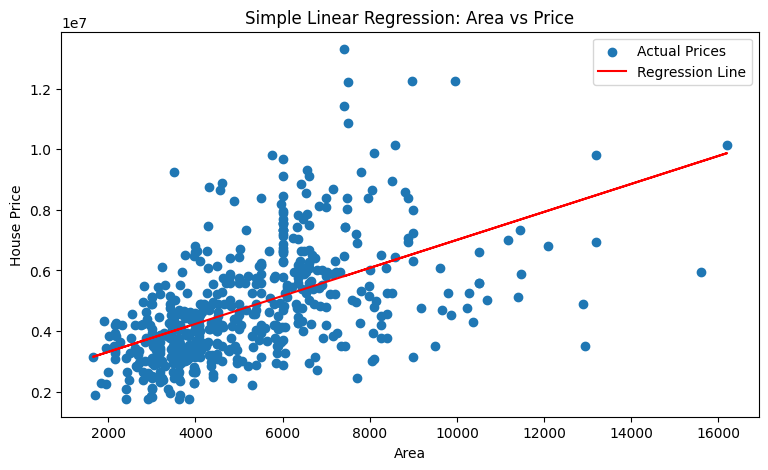

In [27]:
plt.figure(figsize=(9,5))

plt.scatter(x, y, label='Actual Prices')

plt.plot(x, y_pred_manual, color='red', label='Regression Line')

plt.xlabel("Area")
plt.ylabel("House Price")

plt.title("Simple Linear Regression: Area vs Price")

plt.legend()

plt.show()

In [28]:
mse_manual = np.mean((y - y_pred_manual) ** 2)

mae_manual = np.mean(np.abs(y - y_pred_manual))

rmse_manual = np.sqrt(mse_manual)

print("MAE:", mae_manual)
print("MSE:", mse_manual)
print("RMSE:", rmse_manual)

MAE: 1172305.511314891
MSE: 2488861398180.6567
RMSE: 1577612.5627607866


In [29]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [30]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.head(10).values)

print("\nPredicted Prices:")
print(y_pred[:10])

Actual Prices:
[4060000 6650000 3710000 6440000 2800000 4900000 5250000 4543000 2450000
 3353000]

Predicted Prices:
[5203691.70963178 7257004.02115475 3062828.59668171 4559591.65374424
 3332932.30559782 3563080.67918997 5645466.31219972 6413979.66873635
 2755831.54819    2668938.66075228]


In [31]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison.head(15))

    Actual Price  Predicted Price
0        4060000     5.203692e+06
1        6650000     7.257004e+06
2        3710000     3.062829e+06
3        6440000     4.559592e+06
4        2800000     3.332932e+06
5        4900000     3.563081e+06
6        5250000     5.645466e+06
7        4543000     6.413980e+06
8        2450000     2.755832e+06
9        3353000     2.668939e+06
10      10150000     9.570600e+06
11       2660000     2.827432e+06
12       3360000     3.195686e+06
13       3360000     3.352264e+06
14       2275000     3.713879e+06


In [32]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

Model Evaluation
MAE: 979679.6912959901
MSE: 1771751116594.0352
RMSE: 1331071.4167895108
R2 Score: 0.6494754192267803


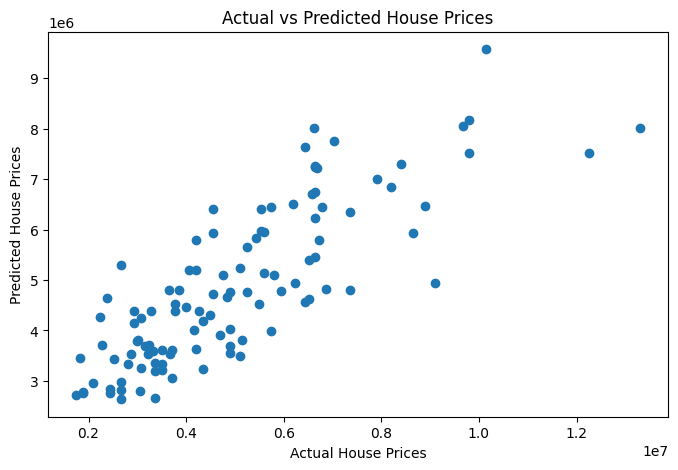

In [33]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [34]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print("Intercept:", model.intercept_)

print("\nCoefficients:")
print(coefficients)

Intercept: -127711.16739244293

Coefficients:
             Feature   Coefficient
0               area  2.358488e+02
1           bedrooms  7.857449e+04
2          bathrooms  1.097117e+06
3            stories  4.062232e+05
4           mainroad  3.668242e+05
5          guestroom  2.331468e+05
6           basement  3.931598e+05
7    hotwaterheating  6.878813e+05
8    airconditioning  7.855506e+05
9            parking  2.257565e+05
10          prefarea  6.299017e+05
11  furnishingstatus  2.103971e+05


In [35]:
new_house = pd.DataFrame([{
    'area': 5000,
    'bedrooms': 3,
    'bathrooms': 2,
    'stories': 2,
    'mainroad': 1,
    'guestroom': 0,
    'basement': 1,
    'hotwaterheating': 0,
    'airconditioning': 1,
    'parking': 2,
    'prefarea': 1,
    'furnishingstatus': 1
}])

predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 7131283.387416512


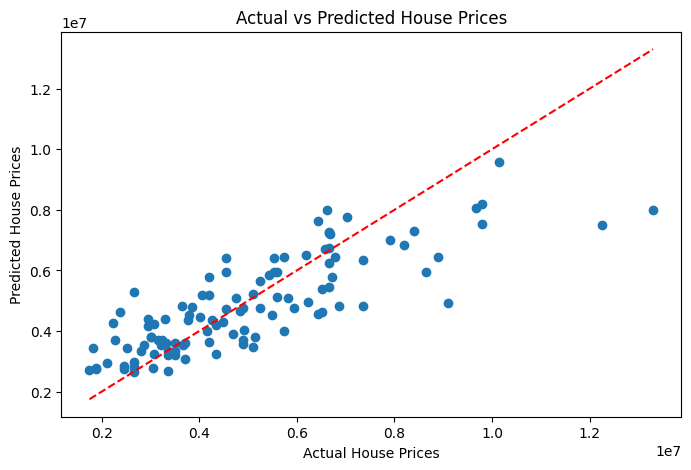

In [36]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

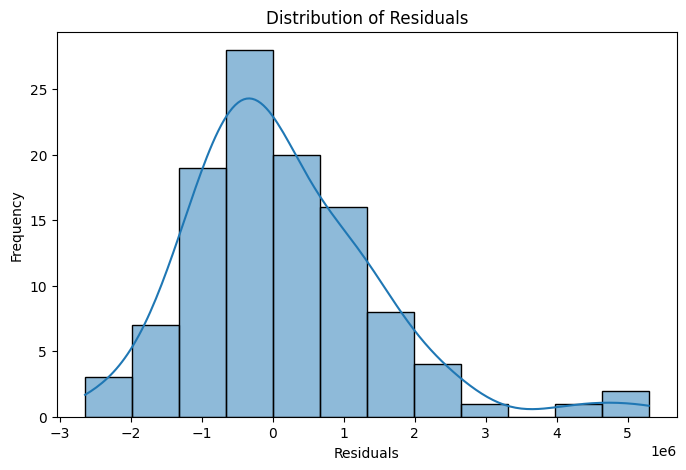

In [37]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

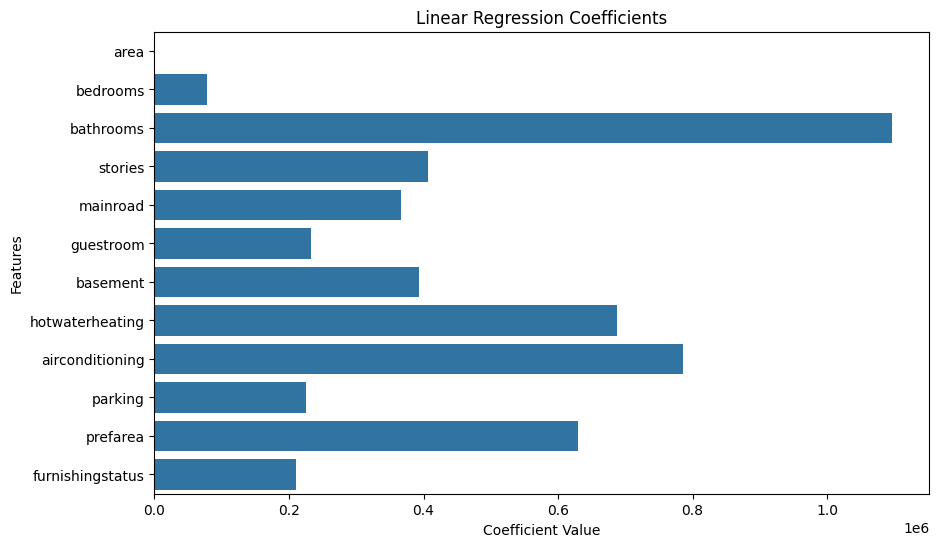

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x='Coefficient',
    y='Feature'
)

plt.title("Linear Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.show()

In [39]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred,
    'Residual': y_test.values - y_pred
})

comparison.to_csv("house_price_predictions.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [40]:
from google.colab import files

files.download("house_price_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [42]:
files.download("house_price_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>